<a href="https://colab.research.google.com/github/afifam24/Machine_learning-/blob/main/Day6_unsupervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

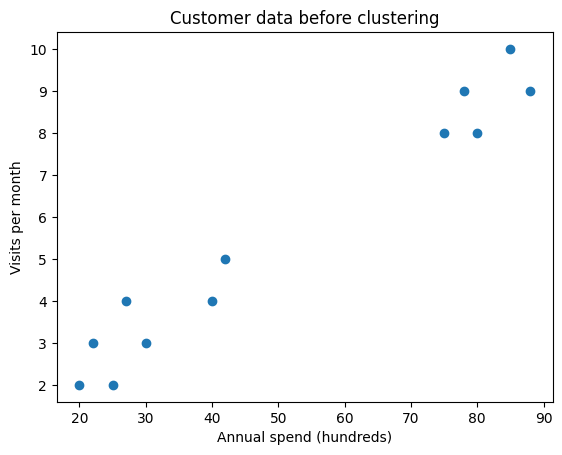

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.DataFrame({
    "AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],
    "VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()



Text(0, 0.5, 'Visits per month')

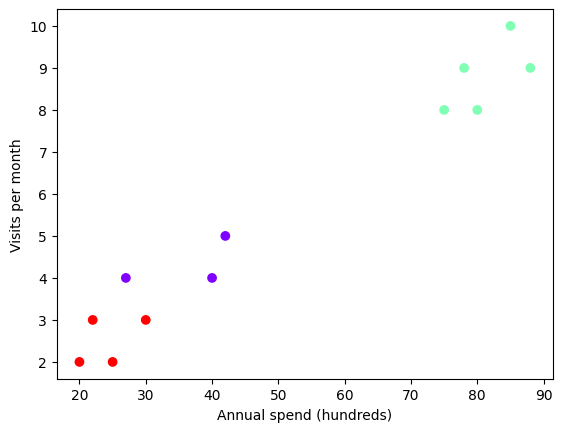

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
scaler=StandardScaler()
X_scaled=scaler.fit_transform(customers)
km=KMeans(n_clusters=3,random_state=42,n_init=10)
customers["cluster"]=km.fit_predict(X_scaled)
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["cluster"],
            cmap="rainbow")
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print(k,
          "inertia:", round(model.inertia_, 2),
          "silhouette:", round(silhouette_score(X_scaled, labels), 3))

2 inertia: 2.03 silhouette: 0.786
3 inertia: 0.97 silhouette: 0.591
4 inertia: 0.66 silhouette: 0.449
5 inertia: 0.38 silhouette: 0.4


Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


Text(0.5, 1.0, 'DBSCAN results (-1 means noise)')

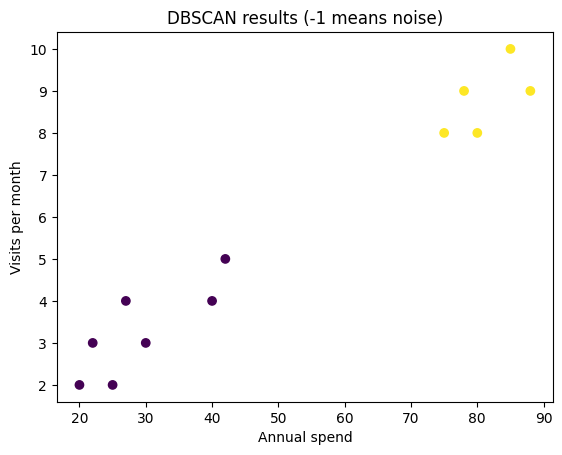

In [ ]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")

Explained variance: [0.73  0.229]


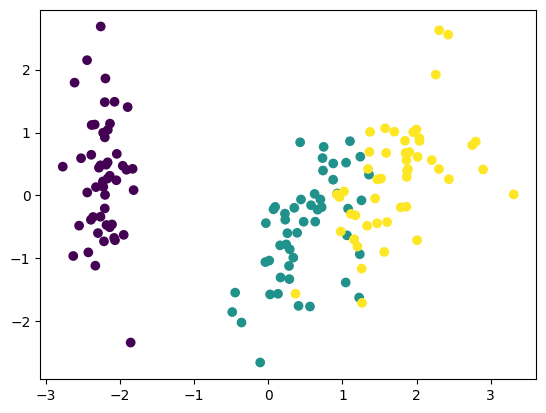

In [ ]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)

print("Explained variance:",
      pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)

In [ ]:
from sklearn.ensemble import IsolationForest
import numpy as np

transactions = np.array([
    [20, 2], [22, 3], [18, 2], [25, 3],
    [21, 2], [23, 4], [19, 3], [250, 20]
])

detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)

for row, label in zip(transactions, labels):
    print(row, "Anomaly" if label == -1 else "Normal")


[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


self assignmet

**bold text**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

df = pd.read_csv("customer_annual_spending_monthly_visits.csv")

df.head()

,Customer_ID,Age,Gender,Annual_Income,Annual_Spending,Visits_Per_Month
0,CUST0001,56,Male,137719,20855,3
1,CUST0002,69,Male,86244,19366,5
2,CUST0003,46,Male,74264,16595,6
3,CUST0004,32,Male,75545,13315,9
4,CUST0005,60,Female,57224,4026,9


In [ ]:
X = df[["Annual_Spending", "Visits_Per_Month"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 1.10921498 -1.29914301]
 [ 0.86846953 -0.42840373]
 [ 0.42044696  0.00696591]
 [-0.10987208  1.31307484]
 [-1.61174206  1.31307484]]


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df.head())

  Customer_ID  Age  Gender  Annual_Income  Annual_Spending  Visits_Per_Month  \
0    CUST0001   56    Male         137719            20855                 3   
1    CUST0002   69    Male          86244            19366                 5   
2    CUST0003   46    Male          74264            16595                 6   
3    CUST0004   32    Male          75545            13315                 9   
4    CUST0005   60  Female          57224             4026                 9   

   Cluster  
0        0  
1        0  
2        0  
3        2  
4        2  


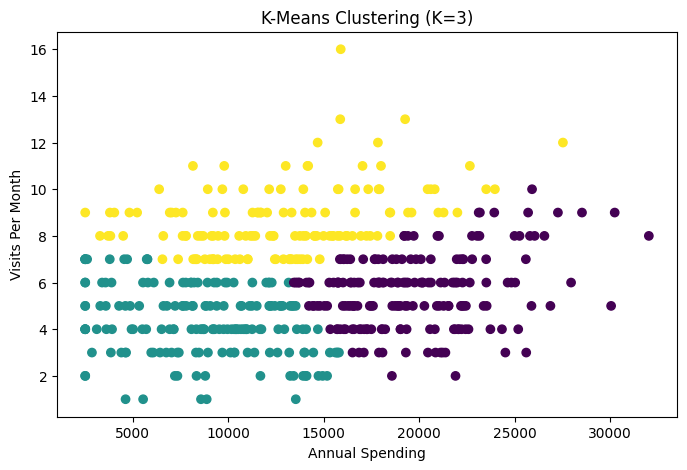

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual_Spending"],
    df["Visits_Per_Month"],
    c=df["Cluster"],
    cmap="viridis"
)

plt.xlabel("Annual Spending")
plt.ylabel("Visits Per Month")
plt.title("K-Means Clustering (K=3)")
plt.show()

In [ ]:
cluster_summary = df.groupby("Cluster").agg(
    Average_Spending=("Annual_Spending", "mean"),
    Average_Visits=("Visits_Per_Month", "mean"),
    Customer_Count=("Customer_ID", "count")
)

print(cluster_summary)

         Average_Spending  Average_Visits  Customer_Count
Cluster                                                  
0            19684.236842        5.621053             190
1             8736.161850        4.271676             173
2            12743.912409        8.649635             137


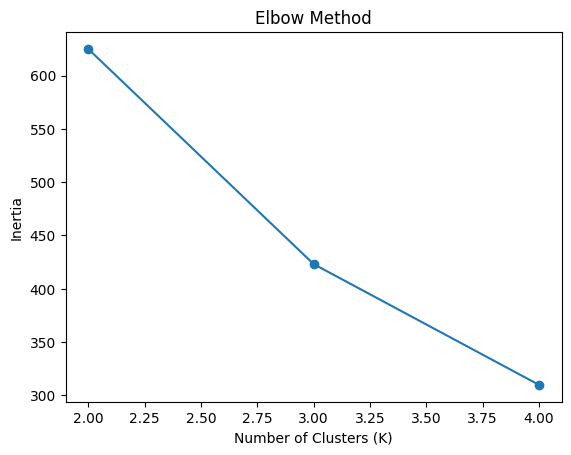

In [ ]:
inertia_values = []

for k in range(2, 5):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.plot(range(2, 5), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

K = 2, Silhouette Score = 0.3396
K = 3, Silhouette Score = 0.3625
K = 4, Silhouette Score = 0.3645


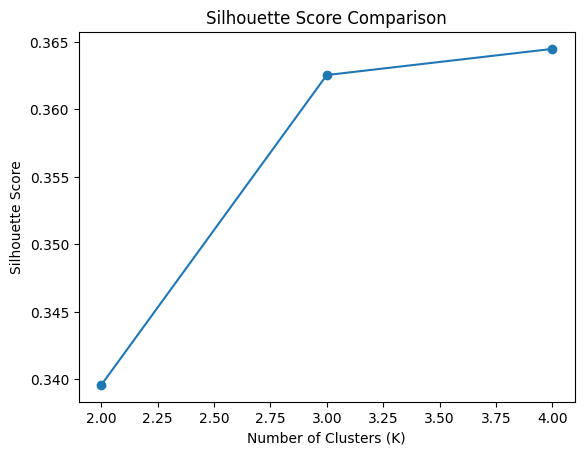

In [ ]:
silhouette_scores = []

for k in range(2, 5):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

plt.plot(range(2, 5), silhouette_scores, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.show()

DBSCAN_Cluster
-1    100
 1     78
 3     78
 0     76
 4     66
 5     46
 6     43
 2     13
Name: count, dtype: int64


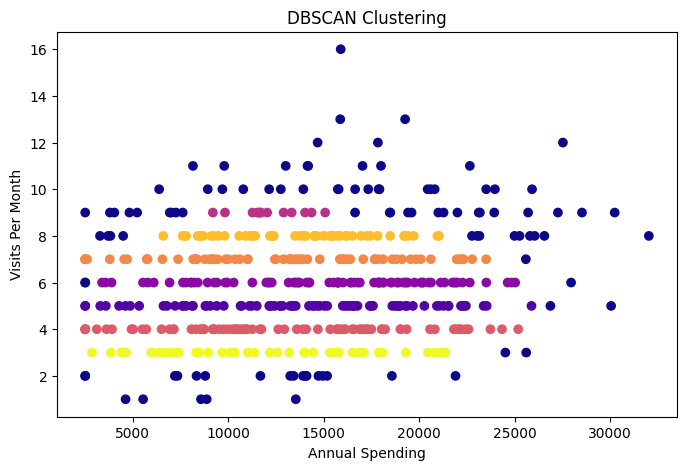

In [ ]:
dbscan = DBSCAN(eps=0.4, min_samples=10)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print(df["DBSCAN_Cluster"].value_counts())

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual_Spending"],
    df["Visits_Per_Month"],
    c=df["DBSCAN_Cluster"],
    cmap="plasma"
)

plt.xlabel("Annual Spending")
plt.ylabel("Visits Per Month")
plt.title("DBSCAN Clustering")
plt.show()

In [ ]:
noise_count = (df["DBSCAN_Cluster"] == -1).sum()

print("Number of noise points:", noise_count)

Number of noise points: 100
